<a href="https://colab.research.google.com/github/Nadaali1232/Women-Safety-Risk-Awareness-Classification/blob/main/Women_Safety_Risk_Awareness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Women Safety Risk-Awareness Classification

**Task.** Classify the contextual safety-risk level of an urban scenario `low`, `medium` or `high` from time, place-context and infrastructure features.

**Main idea.** Each row repeats the statistics of its city, so a model can recognise the *city* instead of learning general patterns. All results here are therefore measured on **cities the model has never seen** (city-grouped cross-validation).

> **Important.** `risk_level` is a *rule-based proxy label*, not real incident data. The model learns the labelling rule. Its outputs are risk-awareness levels, not predictions of real-world crime.

## Table of contents
1. [Setup](#1.-Setup)
2. [The data](#2.-The-data)
3. [Exploring the data](#3.-Exploring-the-data)
4. [Validation: why I hold out whole cities](#4.-Validation:-why-I-hold-out-whole-cities)
5. [Baseline models](#5.-Baseline-models)
6. [Feature reduction and the final model](#6.-Feature-reduction-and-the-final-model)
7. [Explainability](#7.-Explainability)
8. [Limitations](#8.-Limitations)
9. [Save the model](#9.-Save-the-model)

## 1. Setup

In [7]:
import sys, os, glob, json, time, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, lightgbm as lgb
from IPython.display import display, Markdown
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             precision_recall_fscore_support, confusion_matrix)
try:
    import shap
except ImportError:
    get_ipython().run_line_magic('pip', 'install -q shap')
    import shap

SEED = 42
np.random.seed(SEED)
LABELS = ['low', 'medium', 'high']
L2I = {l: i for i, l in enumerate(LABELS)}
COL = {'low': '#4C78A8', 'medium': '#F2B134', 'high': '#C8372D'}      # one colour per class, used in every chart
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

### 1.1 Dataset Loading

In [8]:
DATA_URL = 'https://docs.google.com/spreadsheets/d/1qNeA3MkQ12jkv11ONLCkQy5d-Bkm-A_-FjmNP1WkUtU/edit?usp=sharing'

# Convert Google Sheets sharing link to raw CSV export link
csv_url = DATA_URL.replace('/edit?usp=sharing', '/export?format=csv')

df = pd.read_csv(csv_url)
y = df['risk_level'].map(L2I).values
groups = df['city'].values
print('Loaded', DATA_URL, '->', df.shape)

Loaded https://docs.google.com/spreadsheets/d/1qNeA3MkQ12jkv11ONLCkQy5d-Bkm-A_-FjmNP1WkUtU/edit?usp=sharing -> (489804, 40)


## 2. The data
Each row is one **scenario**: city × day of week × hour × area type × complaint type. The data combines public crime statistics, map-derived infrastructure counts and engineered features. The engineered 0–4 scores are described from the dataset brief and from how they relate to the label (higher = better lighting / access).

| Group | Columns | Varies at | Meaning |
|---|---|---|---|
| **Target** | `risk_level` | row | `low` / `medium` / `high` — a rule-based **proxy label** |
| **Identifiers** (not used as inputs) | `city`, `latitude`, `longitude` | city | Excluded: rows should not identify a place, and they would let a model memorise cities |
| **When** | `day_of_week`, `is_weekend`, `hour` (6, 9, 12, 15, 18, 21, 23), `time_bucket` | row | Time of the scenario |
| **Place context** | `area_context` (7 types), `crowd_density` (low / medium / high) | row | Type of area and how crowded it is |
| **Lighting** | `lighting_score` (1–4), `lighting_data_available` | score: within a city; flag: city | Street-lighting quality; the flag says whether street-light map data existed |
| **Complaint** | `complaint_type_clean` (42 types), `complaint_type_count`, `complaint_type_share`, `complaint_severity` (1–3) | complaint | Kind of women-centric complaint, its count and share, and its severity |
| **City crime statistics** | `women_crime_2021/22/23`, `population_lakhs`, `women_crime_rate_2023`, `chargesheeting_rate_2023`, `women_crime_growth_21_23` | city | Public crime statistics; growth = relative change 2021→2023 |
| **Infrastructure** (map-derived) | police-station count, `nearest_police_station_km`, bus / railway / public-transport counts, `street_light_count_2km`, road length and density, land-use counts, `education_poi_count_5km` | city | Counts within a 2–5 km radius |
| **Engineered scores** | `police_access_score` (0–3), `transport_access_score` (0–3), `urban_density_score` (0–3) | city | Ordinal summaries of the infrastructure counts |

In [9]:
display(df.head(3).T.rename(columns=lambda c: f'row {c}'))
print('rows:', len(df), '| columns:', df.shape[1])
print('missing values:', int(df.isna().sum().sum()), '| duplicate rows:', int(df.duplicated().sum()))
balance = df['risk_level'].value_counts(normalize=True).reindex(LABELS).rename('share')
display(balance.to_frame().style.format('{:.1%}'))

,row 0,row 1,row 2
city,Agra,Agra,Agra
day_of_week,Monday,Monday,Monday
time_bucket,morning,morning,morning
area_context,residential,residential,residential
complaint_type_clean,abetment_to_suicide_of_women,acid_attack,assault_girls_below_18
crowd_density,medium,medium,medium
latitude,27.1767,27.1767,27.1767
longitude,78.0081,78.0081,78.0081
is_weekend,0,0,0
hour,6,6,6


rows: 489804 | columns: 40
missing values: 0 | duplicate rows: 0


,share
risk_level,
low,36.3%
medium,58.8%
high,5.0%


## 3. Exploring the data

### 3.1 How the table is built
The table is a complete grid, and many columns repeat for every row of a city. This matters for how I validate the model.

In [10]:
dims = {c: df[c].nunique() for c in ['city', 'day_of_week', 'hour', 'area_context', 'complaint_type_clean']}
print(dims)
print('full grid =', int(np.prod(list(dims.values()))), '| rows =', len(df), '-> a complete grid')

# Which inputs are identical for every row of a city?
inputs = [c for c in df.columns if c not in ['city', 'latitude', 'longitude', 'risk_level']]
city_constant = [c for c in inputs if df.groupby('city')[c].nunique().max() == 1]
fingerprints = df[city_constant].drop_duplicates().shape[0]
print(f'\n{len(city_constant)} of the {len(inputs)} model inputs are constant within a city.')
print(f'Together they give {fingerprints} distinct combinations for {df.city.nunique()} cities -> a unique "city fingerprint".')

{'city': 34, 'day_of_week': 7, 'hour': 7, 'area_context': 7, 'complaint_type_clean': 42}
full grid = 489804 | rows = 489804 -> a complete grid

25 of the 36 model inputs are constant within a city.
Together they give 34 distinct combinations for 34 cities -> a unique "city fingerprint".


Most inputs are the *same for every row of a city*, and together they identify each city uniquely, even though I never give the model the city name. A flexible model can therefore memorise "this fingerprint ⇒ this city's labels". There are really only **34 independent city-level observations**, so I must validate on whole cities (Section 4).

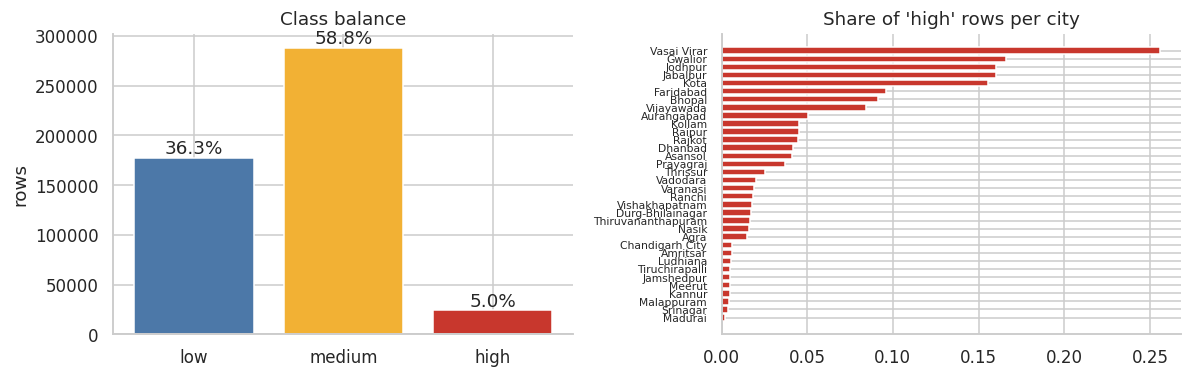

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
vc = df.risk_level.value_counts().reindex(LABELS)
ax[0].bar(LABELS, vc.values, color=[COL[l] for l in LABELS])
for i, v in enumerate(vc.values): ax[0].text(i, v, f'{v/len(df):.1%}', ha='center', va='bottom')
ax[0].set_title('Class balance'); ax[0].set_ylabel('rows')
high_share = df.groupby('city').risk_level.apply(lambda s: (s == 'high').mean()).sort_values()
ax[1].barh(high_share.index, high_share.values, color=COL['high'])
ax[1].set_title("Share of 'high' rows per city"); ax[1].tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()

`high` is only about 5% of rows, and it is concentrated in a minority of cities. So plain accuracy is misleading; I use **macro-F1** (the average F1 of the three classes) as the main metric.

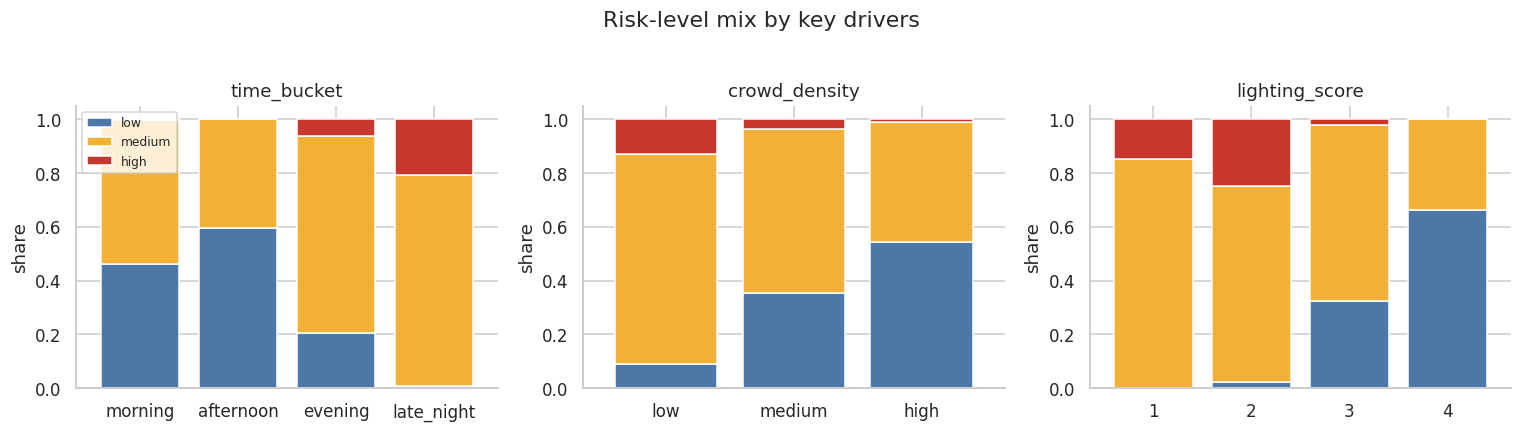

In [12]:
def stacked(ax, col, order=None):
    t = pd.crosstab(df[col], df.risk_level, normalize='index')[LABELS]
    if order is not None: t = t.loc[order]
    t.plot(kind='bar', stacked=True, ax=ax, color=[COL[l] for l in LABELS], width=0.8, legend=False)
    ax.set_title(col); ax.set_xlabel(''); ax.set_ylabel('share'); ax.tick_params(axis='x', rotation=0)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
stacked(axs[0], 'time_bucket', ['morning', 'afternoon', 'evening', 'late_night'])
stacked(axs[1], 'crowd_density', ['low', 'medium', 'high'])
stacked(axs[2], 'lighting_score')
axs[0].legend(LABELS, loc='upper left', fontsize=8)
plt.suptitle('Risk-level mix by key drivers', y=1.03); plt.tight_layout(); plt.show()

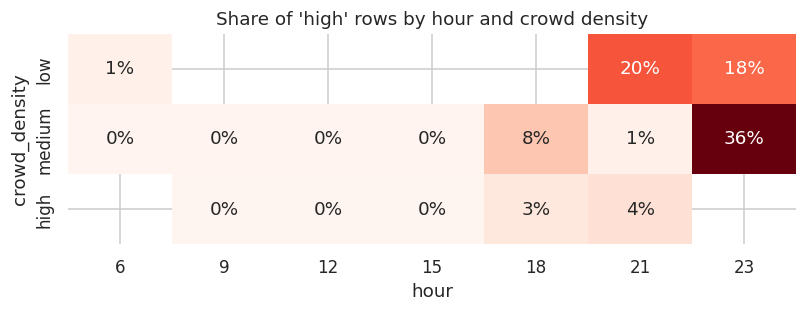

In [13]:
p = df.assign(high=(df.risk_level == 'high')).pivot_table(index='crowd_density', columns='hour', values='high', aggfunc='mean').loc[['low', 'medium', 'high']]
plt.figure(figsize=(7.5, 3)); sns.heatmap(p, annot=True, fmt='.0%', cmap='Reds', cbar=False)
plt.title("Share of 'high' rows by hour and crowd density"); plt.tight_layout(); plt.show()

**What drives the label.** Late-night rows are far more often `high`, low-crowd and poorly lit scenarios likewise, and `high` appears mainly when these **coincide** (late hour + low crowd + poor lighting). That is an interaction, which is why linear models struggle (Section 5).

## 4. Validation: why I hold out whole cities
Rows of the same city share their city-level values, so a random train/test split puts the same city on both sides and rewards memorisation. I use **5-fold cross-validation grouped by city**: every prediction is for a city the model never saw. The comparison below shows how much a random split flatters the model.

In [14]:
cat_cols = ['day_of_week', 'time_bucket', 'area_context', 'complaint_type_clean', 'crowd_density']
NO_LOC = [c for c in df.columns if c not in ['city', 'latitude', 'longitude', 'risk_level']]    # all 36 model inputs

def make_X(cols):
    X = df[cols].copy()
    for c in cat_cols:
        if c in X: X[c] = X[c].astype('category')
    return X
Xall = make_X(NO_LOC)

P = dict(n_estimators=150, learning_rate=0.08, num_leaves=31, min_child_samples=200, subsample=0.7, subsample_freq=1,
         colsample_bytree=0.8, verbose=-1, random_state=SEED, n_jobs=2)                       # main LightGBM settings
Pf = dict(P, n_estimators=60, learning_rate=0.15)                                             # faster settings for the feature study

folds = list(GroupKFold(5).split(df, y, groups))
for i, (a, b) in enumerate(folds):
    print(f'fold {i}: {len(set(groups[b]))} held-out cities, high share {np.mean(y[b] == 2):.1%}')

# Same model, two ways of splitting
rng = np.random.RandomState(SEED)
test_rows = rng.rand(len(df)) < 0.2
m = lgb.LGBMClassifier(**Pf).fit(Xall[~test_rows], y[~test_rows]); pred = m.predict(Xall[test_rows])
random_f1 = f1_score(y[test_rows], pred, average='macro')
a, b = folds[0]
m = lgb.LGBMClassifier(**Pf).fit(Xall.iloc[a], y[a]); pred = m.predict(Xall.iloc[b])
city_f1 = f1_score(y[b], pred, average='macro')
display(Markdown(f'**Random row split:** macro-F1 = **{random_f1:.3f}**  |  **Unseen-city fold:** macro-F1 = **{city_f1:.3f}**'))

fold 0: 7 held-out cities, high share 3.2%
fold 1: 7 held-out cities, high share 5.4%
fold 2: 7 held-out cities, high share 5.2%
fold 3: 7 held-out cities, high share 5.4%
fold 4: 6 held-out cities, high share 5.8%


**Random row split:** macro-F1 = **0.999**  |  **Unseen-city fold:** macro-F1 = **0.779**

The random split looks almost perfect only because the model has seen the other rows of every test city. **The unseen-city number is the honest one**, and it is what the rest of this notebook reports.

## 5. Baseline models
Three baselines, all using the 36 model inputs (no `city`, `latitude` or `longitude`), scored with the same 5 city-grouped folds:

* **Majority-class dummy** - the floor: always predict the most common class.
* **Logistic regression** - a simple linear reference.
* **LightGBM** - gradient-boosted trees; fast on ~490,000 rows, handles categorical columns directly and works with SHAP.

Metrics: **macro-F1** (main), accuracy, `high`-class F1, and **quadratic weighted kappa** (QWK), which punishes low↔high mistakes more than low↔medium because the classes are ordered.

In [15]:
def metrics(yt, pred):
    p, r, f, _ = precision_recall_fscore_support(yt, pred, labels=[0, 1, 2], zero_division=0)
    return dict(macro_f1=f1_score(yt, pred, average='macro'), accuracy=accuracy_score(yt, pred), f1_high=f[2],
                recall_high=r[2], precision_high=p[2], qwk=cohen_kappa_score(yt, pred, weights='quadratic'))

RESULTS, PRED = {}, {}
def record(name, pred):
    PRED[name] = pred
    fold_f1 = [f1_score(y[b], pred[b], average='macro') for _, b in folds]
    RESULTS[name] = {**metrics(y, pred), 'macro_f1_fold_std': float(np.std(fold_f1, ddof=1))}
    r = RESULTS[name]
    print(f"{name:36s} macro-F1 {r['macro_f1']:.3f} (±{r['macro_f1_fold_std']:.3f} across folds) | accuracy {r['accuracy']:.3f}")

def cv_predict(make_model, X):
    pred = np.zeros(len(y), int)
    for a, b in folds:
        pred[b] = make_model().fit(X.iloc[a], y[a]).predict(X.iloc[b])
    return pred

record('Majority-class dummy', np.full(len(y), 1))      # 'medium' is the most common class

num_cols = [c for c in NO_LOC if c not in cat_cols]
make_lr = lambda: make_pipeline(ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols), ('num', StandardScaler(), num_cols)]),
                                LogisticRegression(max_iter=200, class_weight='balanced'))
t = time.time(); record('Logistic regression (36 features)', cv_predict(make_lr, df[NO_LOC])); print(f'   [{time.time()-t:.0f}s]')
t = time.time(); record('LightGBM (36 features)', cv_predict(lambda: lgb.LGBMClassifier(**P), Xall)); print(f'   [{time.time()-t:.0f}s]')

Majority-class dummy                 macro-F1 0.247 (±0.012 across folds) | accuracy 0.588
Logistic regression (36 features)    macro-F1 0.697 (±0.045 across folds) | accuracy 0.756
   [323s]
LightGBM (36 features)               macro-F1 0.841 (±0.077 across folds) | accuracy 0.896
   [165s]


Trees clearly beat the linear model: the label depends on **interactions** between features (for example late hour × low crowd × poor lighting), which a linear model cannot express.

## 6. Feature reduction and the final model
Because there are only 34 cities, giving a flexible model many city-level columns lets it fit city identity. A raw count (population, road length…) mostly says *which city* a row belongs to, while a rate, growth figure or distance is comparable between cities.

**Method.** Start from a **core set** of 15 features (the row-level drivers, the engineered scores and the crime rate). Add each remaining column **one at a time** and measure the change in unseen-city macro-F1. **Rule:** keep a column if it adds more than **+0.015** macro-F1.

core set (15 features): macro-F1 0.819   [1046s]


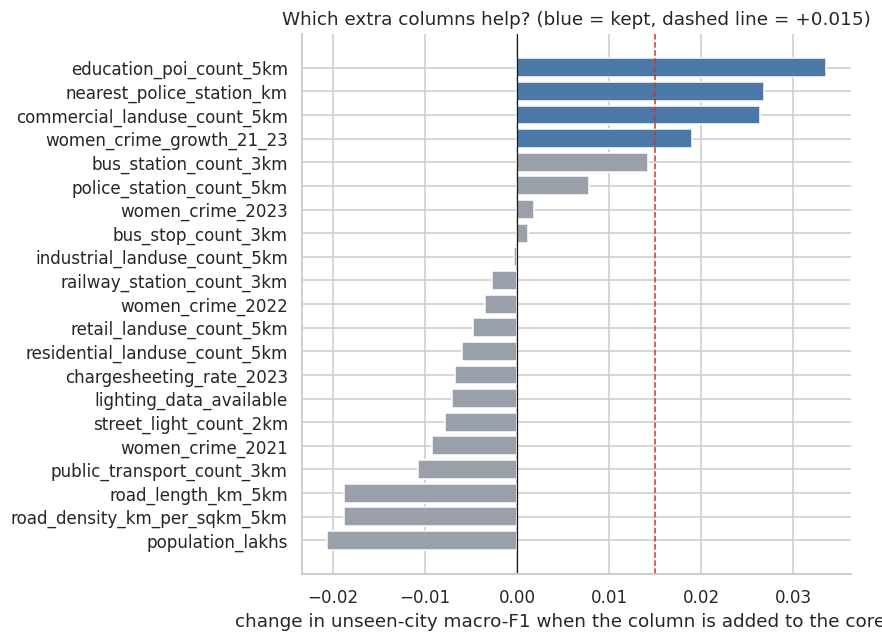

**Kept 4 columns:** `education_poi_count_5km`, `nearest_police_station_km`, `commercial_landuse_count_5km`, `women_crime_growth_21_23`  →  final feature set = 15 core + 4 = **19 features**.

In [16]:
core = ['day_of_week', 'time_bucket', 'area_context', 'complaint_type_clean', 'crowd_density', 'is_weekend', 'hour',
        'complaint_type_count', 'complaint_type_share', 'complaint_severity', 'lighting_score',
        'police_access_score', 'transport_access_score', 'urban_density_score', 'women_crime_rate_2023']
candidates = [c for c in NO_LOC if c not in core]
THRESHOLD = 0.015

def fast_macro_f1(cols):
    X = Xall[cols]
    pred = cv_predict(lambda: lgb.LGBMClassifier(**Pf), X)
    return f1_score(y, pred, average='macro')

t = time.time()
base = fast_macro_f1(core)
gain = pd.Series({c: fast_macro_f1(core + [c]) - base for c in candidates}).sort_values(ascending=False)
print(f'core set ({len(core)} features): macro-F1 {base:.3f}   [{time.time()-t:.0f}s]')

kept = gain[gain > THRESHOLD].index.tolist()
SEL = core + kept

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(gain.index[::-1], gain.values[::-1], color=[COL['low'] if v > THRESHOLD else '#9AA0AA' for v in gain.values[::-1]])
ax.axvline(0, color='k', lw=0.8); ax.axvline(THRESHOLD, color=COL['high'], ls='--', lw=1)
ax.set_xlabel('change in unseen-city macro-F1 when the column is added to the core set')
ax.set_title(f'Which extra columns help? (blue = kept, dashed line = +{THRESHOLD})')
plt.tight_layout(); plt.show()
display(Markdown(f'**Kept {len(kept)} columns:** ' + ', '.join(f'`{c}`' for c in kept) + f'  →  final feature set = {len(core)} core + {len(kept)} = **{len(SEL)} features**.'))

**Reading the chart.** Four columns help clearly (two counts of nearby facilities, the distance to the nearest police station and the crime growth rate); many are neutral and some *hurt*, most visibly population and road length/density. With only 34 cities I do not claim to know why each column helps, only that adding it improved unseen-city results here.

*Note:*  the columns were chosen using the same folds that I score on, so the result below is slightly optimistic. With only 34 cities, small differences should not be over-interpreted.

In [17]:
t = time.time(); Xsel = make_X(SEL)
record('LightGBM (reduced feature set)', cv_predict(lambda: lgb.LGBMClassifier(**P), Xsel)); print(f'   [{time.time()-t:.0f}s]')

order = ['Majority-class dummy', 'Logistic regression (36 features)', 'LightGBM (36 features)', 'LightGBM (reduced feature set)']
table = pd.DataFrame(RESULTS).T.loc[order][['macro_f1', 'macro_f1_fold_std', 'accuracy', 'f1_high', 'recall_high', 'precision_high', 'qwk']]
table.columns = ['Macro-F1', 'Macro-F1 std (folds)', 'Accuracy', 'High F1', 'High recall', 'High precision', 'QWK']
display(table.round(3))

LightGBM (reduced feature set)       macro-F1 0.889 (±0.050 across folds) | accuracy 0.923
   [126s]


,Macro-F1,Macro-F1 std (folds),Accuracy,High F1,High recall,High precision,QWK
Majority-class dummy,0.247,0.012,0.588,0.000,0.000,0.000,0.000
Logistic regression (36 features),0.697,0.045,0.756,0.548,0.886,0.397,0.662
LightGBM (36 features),0.841,0.077,0.896,0.720,0.639,0.824,0.831
LightGBM (reduced feature set),0.889,0.050,0.923,0.815,0.738,0.910,0.875


**Result.** Reducing 36 features to 19 raises macro-F1 from **0.841** to **0.889** and `high`-class F1 from 0.720 to 0.815. The spread across folds is about ±0.05, so which cities land in a fold matters as much as the model.

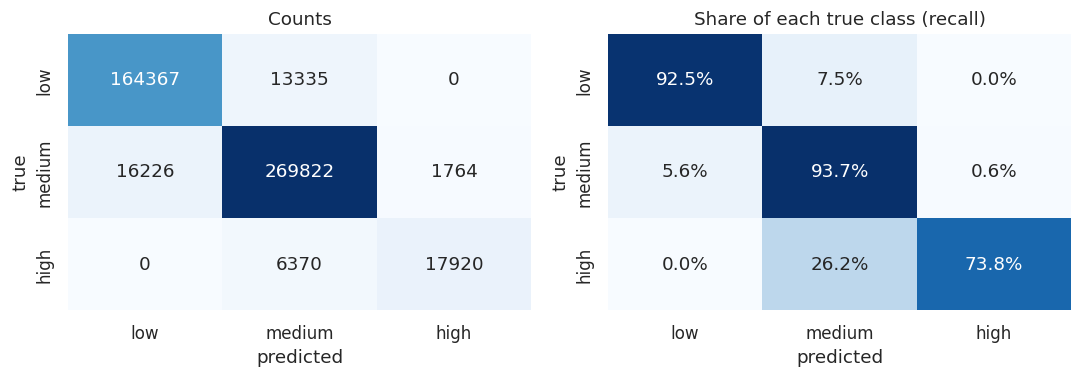

Low-to-high or high-to-low mistakes: **0** rows. Errors are between neighbouring levels, and the main weakness is `high` rows predicted as `medium` (recall 74%).

In [18]:
r36, rsel = RESULTS['LightGBM (36 features)'], RESULTS['LightGBM (reduced feature set)']
display(Markdown(f"**Result.** Reducing 36 features to {len(SEL)} raises macro-F1 from **{r36['macro_f1']:.3f}** to **{rsel['macro_f1']:.3f}** "
                 f"and `high`-class F1 from {r36['f1_high']:.3f} to {rsel['f1_high']:.3f}. The spread across folds is about ±{rsel['macro_f1_fold_std']:.2f}, "
                 f"so which cities land in a fold matters as much as the model."))
final_pred = PRED['LightGBM (reduced feature set)']
cm = confusion_matrix(y, final_pred); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a_, M, fmt, ttl in [(ax[0], cm, 'd', 'Counts'), (ax[1], cmn, '.1%', 'Share of each true class (recall)')]:
    sns.heatmap(M, annot=True, fmt=fmt, cmap='Blues', cbar=False, xticklabels=LABELS, yticklabels=LABELS, ax=a_)
    a_.set_xlabel('predicted'); a_.set_ylabel('true'); a_.set_title(ttl)
plt.tight_layout(); plt.show()
display(Markdown(f'Low-to-high or high-to-low mistakes: **{cm[0, 2] + cm[2, 0]}** rows. Errors are between neighbouring levels, and the main weakness is `high` rows predicted as `medium` (recall {cmn[2, 2]:.0%}).'))

## 7. Explainability
Three views of what the final model has learned:
1. **SHAP summary** — which features push a scenario towards `high`.
2. **Importance by concept** — related columns grouped, so the story is not split across many columns.
3. **Surrogate decision tree** — a small readable tree that imitates the model, to expose the rule structure.

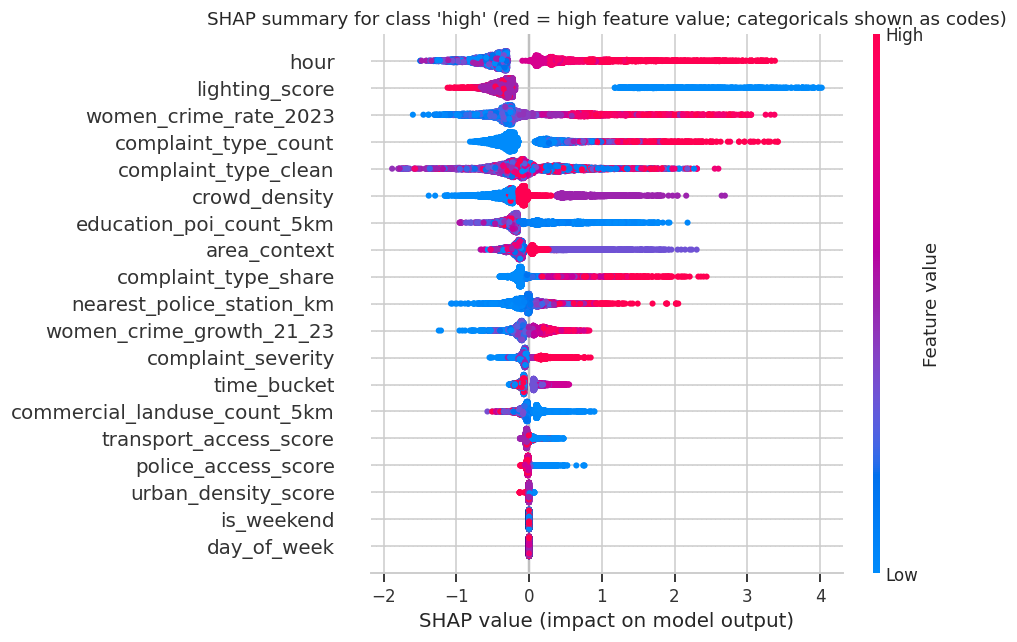

**Strongest drivers of `high`:** `hour`, `lighting_score`, `women_crime_rate_2023`, `complaint_type_count`, `complaint_type_clean`.

In [19]:
clf = lgb.LGBMClassifier(**P).fit(Xsel, y)
idx = np.random.RandomState(SEED).choice(len(df), 6000, replace=False)
Xs = Xsel.iloc[idx]
explainer = shap.TreeExplainer(clf)
sv_raw = explainer.shap_values(Xs)
sv = np.stack(sv_raw, axis=-1) if isinstance(sv_raw, list) else sv_raw         # rows x features x classes
Xs_num = Xs.copy()
for c in cat_cols: Xs_num[c] = Xs_num[c].cat.codes

plt.figure()
shap.summary_plot(sv[:, :, 2], Xs_num, show=False, max_display=len(SEL), plot_size=(9, 6))
plt.title("SHAP summary for class 'high' (red = high feature value; categoricals shown as codes)")
plt.tight_layout(); plt.show()

top = pd.Series(np.abs(sv[:, :, 2]).mean(0), index=Xs.columns).sort_values(ascending=False)
display(Markdown('**Strongest drivers of `high`:** ' + ', '.join(f'`{c}`' for c in top.index[:5]) + '.'))

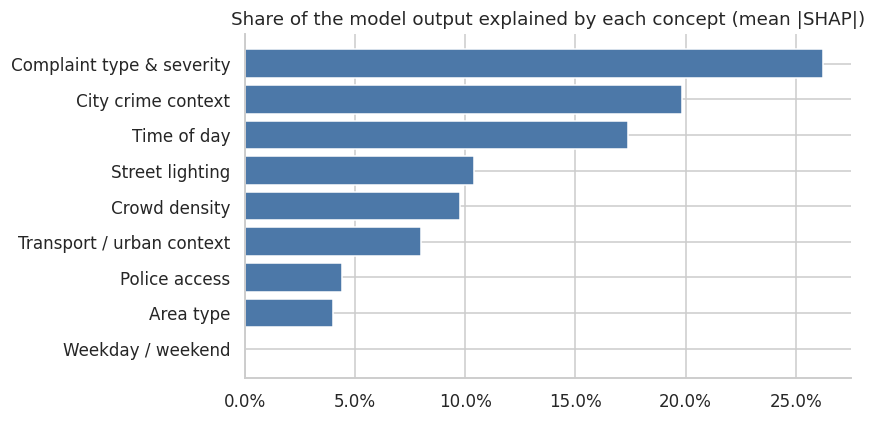

**By concept:** Complaint type & severity 26%, City crime context 20%, Time of day 17%, Street lighting 10%, Crowd density 10%, Transport / urban context 8%, Police access 4%, Area type 4%, Weekday / weekend 0%.

In [20]:
concepts = {
    'Complaint type & severity': ['complaint_type_clean', 'complaint_type_count', 'complaint_type_share', 'complaint_severity'],
    'Time of day': ['hour', 'time_bucket'],
    'Weekday / weekend': ['day_of_week', 'is_weekend'],
    'Crowd density': ['crowd_density'],
    'Street lighting': ['lighting_score'],
    'Area type': ['area_context'],
    'City crime context': ['women_crime_rate_2023', 'women_crime_growth_21_23', 'women_crime_2023'],
    'Police access': ['police_access_score', 'nearest_police_station_km', 'police_station_count_5km'],
    'Transport / urban context': ['transport_access_score', 'urban_density_score', 'bus_station_count_3km', 'bus_stop_count_3km',
                                  'commercial_landuse_count_5km', 'education_poi_count_5km'],
}
imp = pd.Series(np.abs(sv).mean(axis=(0, 2)), index=Xs.columns)          # average over rows and classes
named = {c: k for k, v in concepts.items() for c in v}
concept_imp = imp.groupby(imp.index.map(lambda c: named.get(c, 'Other city features'))).sum().sort_values()
share = concept_imp / concept_imp.sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(share.index, share.values, color=COL['low']); ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title('Share of the model output explained by each concept (mean |SHAP|)'); plt.tight_layout(); plt.show()
display(Markdown('**By concept:** ' + ', '.join(f'{k} {v:.0%}' for k, v in share[::-1].items()) + '.'))

In [21]:
# Surrogate tree: a small tree trained to imitate the model's predictions
Z = pd.DataFrame({'hour': df.hour, 'is_late_night': (df.time_bucket == 'late_night').astype(int),
                  'crowd_low': (df.crowd_density == 'low').astype(int), 'crowd_high': (df.crowd_density == 'high').astype(int),
                  'lighting_score': df.lighting_score, 'police_access_score': df.police_access_score,
                  'complaint_severity': df.complaint_severity, 'crime_rate_2023': df.women_crime_rate_2023,
                  'crime_growth': df.women_crime_growth_21_23, 'nearest_police_km': df.nearest_police_station_km})
for d in (3, 4, 6):
    s = DecisionTreeClassifier(max_depth=d, min_samples_leaf=500, random_state=SEED).fit(Z, final_pred)
    print(f'depth {d}: matches the model on {accuracy_score(final_pred, s.predict(Z)):.1%} of rows')
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=500, random_state=SEED).fit(Z, final_pred)
print()
print(export_text(tree, feature_names=list(Z.columns), class_names=LABELS))

depth 3: matches the model on 77.7% of rows
depth 4: matches the model on 81.5% of rows
depth 6: matches the model on 86.9% of rows

|--- hour <= 16.50
|   |--- crime_rate_2023 <= 110.80
|   |   |--- crowd_high <= 0.50
|   |   |   |--- complaint_severity <= 1.50
|   |   |   |   |--- class: low
|   |   |   |--- complaint_severity >  1.50
|   |   |   |   |--- class: medium
|   |   |--- crowd_high >  0.50
|   |   |   |--- complaint_severity <= 2.50
|   |   |   |   |--- class: low
|   |   |   |--- complaint_severity >  2.50
|   |   |   |   |--- class: low
|   |--- crime_rate_2023 >  110.80
|   |   |--- crowd_high <= 0.50
|   |   |   |--- complaint_severity <= 1.50
|   |   |   |   |--- class: medium
|   |   |   |--- complaint_severity >  1.50
|   |   |   |   |--- class: medium
|   |   |--- crowd_high >  0.50
|   |   |   |--- complaint_severity <= 1.50
|   |   |   |   |--- class: low
|   |   |   |--- complaint_severity >  1.50
|   |   |   |   |--- class: medium
|--- hour >  16.50
|   |--- li

**Reading the tree (depth 4, matches the model on 81.5% of rows; depth 6 reaches 86.9%).**
* **Daytime (hour ≤ 16):** never `high`. Low city crime rate (≤ 110.8) gives mostly `low`; a higher crime rate or a more severe complaint pushes towards `medium`.
* **Evening / night (hour > 16):** `high` appears only when **lighting is poor (score ≤ 2) and the city crime rate is above about 152.7**. Good lighting (score 4) keeps scenarios at `low` or `medium`.
* The splits at about 110.8 and 152.7 on the city crime rate look like the bands of the labelling rule, which fits the idea that the model is recovering a rule-based proxy label.

## 8. Limitations
* **The labels are proxies.** `risk_level` is generated by a rule. A `high` prediction means "this scenario matches the rule's definition of risky", not "a crime is likely". The readable surrogate tree above is a sign of how rule-like the labels are.
* **Only 34 cities.** Nearly half a million rows, but only 34 independent city-level observations. Scores move noticeably depending on which cities fall in a fold, and small differences between models should not be over-interpreted.
* **Feature choice used the same folds as the evaluation**, so the final score is slightly optimistic.
* **City-level data and map gaps.** Crime figures are city-level, and map-derived features (especially street lighting) can be incomplete.
* **City-level inputs partly encode which city a scenario is in.** Results should not be used to stigmatise places.
* **Not for operational use:** not an emergency system, a policing tool, an individual risk score or a real-time crime predictor.

**Possible next steps:** more cities (the real bottleneck), real incident-level labels, and a stricter evaluation that repeats the feature selection inside each fold.

## 9. Save the model
Saves the final model with what is needed to use it, plus a short example.

In [23]:
cat_levels = {c: list(df[c].astype('category').cat.categories) for c in cat_cols}
bundle = dict(model=clf, features=SEL, categorical_levels=cat_levels, labels=LABELS,
              note='risk-awareness level from a rule-based proxy label; not a prediction of real-world crime')
joblib.dump(bundle, 'women_safety_risk_awareness_model.joblib')

def predict_risk(rows):
    X = rows[bundle['features']].copy()
    for c, lv in bundle['categorical_levels'].items():
        if c in X: X[c] = pd.Categorical(X[c], categories=lv)
    p = bundle['model'].predict_proba(X)
    return pd.DataFrame({'risk_level': [LABELS[i] for i in p.argmax(1)], 'p_low': p[:, 0].round(3), 'p_medium': p[:, 1].round(3), 'p_high': p[:, 2].round(3)}, index=rows.index)

demo = df.sample(6, random_state=1)
display(pd.concat([demo[['hour', 'area_context', 'crowd_density', 'lighting_score', 'risk_level']].rename(columns={'risk_level': 'true level'}), predict_risk(demo)], axis=1))
print('women_safety_risk_awareness_model.joblib')

summary = {k: {m: float(v) for m, v in r.items()} for k, r in RESULTS.items()}
summary['_selected_features'] = SEL
json.dump(summary, open('results.json', 'w'), indent=1)

,hour,area_context,crowd_density,lighting_score,true level,risk_level,p_low,p_medium,p_high
346023,6,mixed,medium,3,low,low,0.976,0.024,0.000
223777,21,commercial,high,3,medium,medium,0.000,0.998,0.002
219767,21,industrial,low,2,high,high,0.000,0.037,0.963
458948,6,residential,medium,3,medium,medium,0.000,0.937,0.063
17998,21,commercial,high,3,low,low,0.999,0.001,0.000
270293,12,market,high,4,low,low,1.000,0.000,0.000


women_safety_risk_awareness_model.joblib
